# Baseline Model Tuning: Logistic Regression
Follow-up to `03_baseline_model_testing.ipynb`, which compared 5 models with their starting settings. This notebook **tunes Logistic Regression**: it searches for better settings (hyperparameters) and chooses the Disrupted decision threshold.

**Why Logistic Regression:** it is the simple, easy-to-explain reference model. In 03 it had the lowest macro-F1 (0.520), but only with the default rule; with its own threshold it does much better. Tuning shows how close a simple model can get to the tree models, which matters for explaining the results.

**How tuning is organized:** each algorithm is tuned in its own notebook (`03_2_baseline_model_tuning_lightgbm`, `03_2_baseline_model_tuning_random_forest`, `03_2_baseline_model_tuning_catboost`, `03_2_baseline_model_tuning_xgboost`, `03_2_baseline_model_tuning_logistic_regression`), and a later notebook compares them. To make the comparison fair, every tuning notebook uses the shared setup in `tuning_setup.py` (same training rows, same 5 folds, same scores, same threshold method) and saves its results in the same format to `results/tuning/<model>/`.

**The test set is still not used.** Only the final comparison notebook will score it, once.

Steps:
1. Load the training data and the shared setup
2. Score untuned Logistic Regression as the starting point
3. Define which settings to search, and over what ranges
4. Run a randomized search with stratified 5-fold cross-validation
5. Compare tuned vs. untuned, fold by fold
6. Choose the Disrupted threshold
7. Save the results

## 1. Load Data & Shared Setup
`tuning_setup.py` (in this folder) holds everything the tuning notebooks share:
- `load_training_data()`: the **training rows only** of `model_ready.csv`, with the target encoded as Normal = 0, Delayed = 1, Disrupted = 2 (same as 03)
- `make_folds()`: the **same 5 stratified folds as 03** (`shuffle=True, random_state=42`), so scores here can be compared directly with 03
- `score_predictions()` / `score_folds()`: the same scores as 03 (macro-F1, F1 per status, Disrupted precision/recall/PR-AUC, ROC-AUC)
- threshold helpers and `save_tuning_results()`, explained in sections 6 and 7

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from scipy.stats import loguniform, randint, uniform
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict

from tuning_setup import (DISRUPTED, SEARCH_SCORING, STATUS_ORDER, THRESHOLDS, best_threshold_macro_f1,
                          choose_threshold, cross_validated_threshold, load_training_data, make_folds,
                          predict_with_threshold, save_tuning_results, score_folds, score_predictions)

train_df, X_train, y_train = load_training_data()
folds = make_folds(X_train, y_train)

print("Training rows:", len(X_train))
print(f"{X_train.shape[1]} features: {', '.join(X_train.columns)}")
print("Disrupted rows per held-out fold:", [int((y_train.iloc[valid_index] == DISRUPTED).sum()) for _, valid_index in folds])

Training rows: 25040
7 features: geopolitical_risk_score, port_congestion_index, weather_disruption_score, origin_active_event_risk, destination_active_event_risk, covid_supply_shock_active, russia_ukraine_war_active
Disrupted rows per held-out fold: [159, 160, 160, 160, 160]


## 2. Starting Point: Untuned Logistic Regression
The same model as in 03: the features are put on the same scale (`StandardScaler`), then a Logistic Regression with its default settings is trained.

It is written as a 3-step `Pipeline` so the search in section 4 can change each step:
1. `splines`: optional extra features (see section 3). `"passthrough"` means "skip this step", as in 03
2. `scale`: put every feature on the same scale
3. `model`: the Logistic Regression itself

One small change from 03: the class weights are set with Logistic Regression's own `class_weight="balanced"` option instead of passing `sample_weight`. It uses the **same formula** (`rows / (3 x rows with that status)`), computed inside each fold automatically.

`cross_val_predict` trains one model per fold and returns each row's probabilities from the model that **didn't** see it (out-of-fold probabilities, as in 03).

In [2]:
untuned_model = Pipeline([
    ("splines", "passthrough"),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000)),
])

untuned_probabilities = cross_val_predict(untuned_model, X_train, y_train, cv=folds, method="predict_proba")
untuned_fold_scores = score_folds(y_train, untuned_probabilities, folds)

untuned_fold_scores.agg(["mean", "std"]).round(3)

,macro_f1,f1_normal,f1_delayed,f1_disrupted,disrupted_precision,disrupted_recall,disrupted_pr_auc,roc_auc_ovr
mean,0.520,0.689,0.635,0.238,0.140,0.790,0.280,0.832
std,0.004,0.006,0.006,0.012,0.007,0.031,0.042,0.004


These are exactly the Logistic Regression scores from 03 (macro-F1 0.520 ± 0.004, Disrupted recall 0.790, Disrupted PR-AUC 0.280). This confirms that `class_weight="balanced"` gives the same result as the `sample_weight` approach in 03, and that the folds are the same. This is the starting point tuning has to beat.

## 3. Search Space
Logistic Regression has few settings of its own. Its main limit is that it can only learn **straight-line** relationships: "the higher the risk, the more likely a disruption", at the same rate everywhere. It can't learn shapes like "risk only matters above 60".

So the search also tries **spline features**: each feature is replaced by a few smooth, bendable pieces (`SplineTransformer`), which lets the model learn curved relationships while staying a Logistic Regression. More cut points (`n_knots`) allow more bends.

| Setting | What it controls | Options searched | Why it matters |
|---|---|---|---|
| `splines` | Whether to add spline features, and how flexible they are | none (`passthrough`), or splines with 4, 6 or 10 cut points | Lets a linear model learn curved relationships |
| `model__C` | How strongly the model is held back (smaller C = stronger penalty) | 0.001 to 100 (log scale) | A stronger penalty prevents overfitting, especially with many spline features |
| `model__l1_ratio` | Type of penalty: 0 = L2 (shrinks all weights), 1 = L1 (can set weights to exactly 0) | 0 to 1 | L1 can switch off unhelpful features or spline pieces |

The fixed settings: `class_weight="balanced"` (as in section 2) and the `saga` solver, which supports every `l1_ratio`. `max_iter=3000` gives the solver enough steps to finish.

In [3]:
search_space = {
    "splines": ["passthrough", SplineTransformer(n_knots=4), SplineTransformer(n_knots=6), SplineTransformer(n_knots=10)],
    "model__C": loguniform(0.001, 100),
    "model__l1_ratio": uniform(0, 1),
}

base_model = Pipeline([
    ("splines", "passthrough"),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", solver="saga", max_iter=3000)),
])

## 4. Randomized Search
**Randomized search** tries a fixed number of random combinations from the ranges above. Trying every combination (a grid search) would take thousands of combinations; a random sample of combinations usually finds settings about as good for a small fraction of the time, because only a few settings matter a lot and random sampling tries many different values of each.

**Setup:**
- **60 combinations**, each scored with the **same 5 stratified folds** (300 models in total)
- **macro-F1 at the best threshold picks the winner** (`macro_f1_best_threshold`, see below). macro-F1 with the default rule, Disrupted PR-AUC and ROC-AUC are recorded too

**Why "at the best threshold":** every final model gets its own Disrupted threshold (section 7). If combinations were compared with the default rule (highest probability wins), the search would mostly reward settings whose default rule happens to fall near a good cut-off. For example, with class weights, models with bigger leaves call Disrupted more often under the default rule: their default-rule macro-F1 drops, even though they rank disruptions just as well and do fine once their threshold is set. So each combination is scored by the macro-F1 it reaches with its **best** threshold on each held-out fold. Picking the threshold on the same fold it is scored on is slightly optimistic, but equally so for every combination; section 7 gives the honest estimate.
- `n_jobs=-1` trains several models at the same time on all CPU cores (each model uses 1 core)

**Run time:** about 8 minutes (a few combinations with weak penalties take up to 3 minutes each, because the solver needs many steps) on a 24-core machine. On a laptop with fewer cores it will take longer; lowering `n_iter` makes it faster but searches fewer combinations.

In [4]:
search = RandomizedSearchCV(
    base_model,
    param_distributions=search_space,
    n_iter=60,
    scoring=SEARCH_SCORING,
    refit="macro_f1_best_threshold",   # the best combination is chosen by macro-F1 at its best threshold
    cv=folds,
    n_jobs=-1,
    random_state=42,
    return_train_score=True,   # also keep scores on the training folds, to spot overfitting
)

start = time.perf_counter()
search.fit(X_train, y_train)
print(f"Search finished in {time.perf_counter() - start:.0f} seconds")

Search finished in 471 seconds


## 5. Search Results
The table shows the 10 best combinations by mean `macro_f1_best_threshold` across the 5 folds. `train macro_f1_best_threshold` is the same score on the rows the model **was** trained on: a big gap between train and held-out scores means the model is memorizing its training rows. `macro_f1 (default rule)` is shown for reference.

In [5]:
results_df = pd.DataFrame(search.cv_results_)
param_columns = [f"param_{name}" for name in search_space]

score_names = {
    "mean_test_macro_f1_best_threshold": "macro_f1_best_threshold",
    "std_test_macro_f1_best_threshold": "std across folds",
    "mean_train_macro_f1_best_threshold": "train macro_f1_best_threshold",
    "mean_test_macro_f1": "macro_f1 (default rule)",
    "mean_test_disrupted_pr_auc": "disrupted_pr_auc",
    "mean_test_roc_auc_ovr": "roc_auc_ovr",
    "mean_fit_time": "fit seconds",
}
search_results_df = (
    results_df[param_columns + list(score_names)]
    .rename(columns={**{f"param_{name}": name for name in search_space}, **score_names})
    .sort_values("macro_f1_best_threshold", ascending=False)
    .reset_index(drop=True)
)

search_results_df.head(10).round(3)

,splines,model__C,model__l1_ratio,macro_f1_best_threshold,std across folds,train macro_f1_best_threshold,macro_f1 (default rule),disrupted_pr_auc,roc_auc_ovr,fit seconds
0,SplineTransformer(n_knots=10),0.121,0.883,0.608,0.008,0.609,0.527,0.323,0.836,25.751
1,SplineTransformer(n_knots=10),0.006,0.058,0.608,0.006,0.609,0.527,0.323,0.836,3.358
2,SplineTransformer(n_knots=10),0.014,0.241,0.608,0.006,0.609,0.527,0.323,0.836,6.388
3,SplineTransformer(n_knots=10),0.114,0.033,0.608,0.008,0.609,0.527,0.322,0.835,19.746
4,SplineTransformer(n_knots=10),0.042,0.730,0.608,0.007,0.609,0.526,0.323,0.836,17.406
5,SplineTransformer(n_knots=10),0.859,0.965,0.608,0.008,0.609,0.527,0.322,0.835,181.885
6,SplineTransformer(n_knots=10),42.806,0.651,0.608,0.007,0.610,0.527,0.322,0.835,183.976
7,SplineTransformer(n_knots=10),49.291,0.001,0.608,0.007,0.610,0.527,0.322,0.835,186.969
8,SplineTransformer(n_knots=10),1.146,0.139,0.608,0.008,0.609,0.527,0.322,0.835,125.148
9,SplineTransformer(n_knots=10),7.265,0.199,0.608,0.008,0.610,0.527,0.322,0.835,184.811


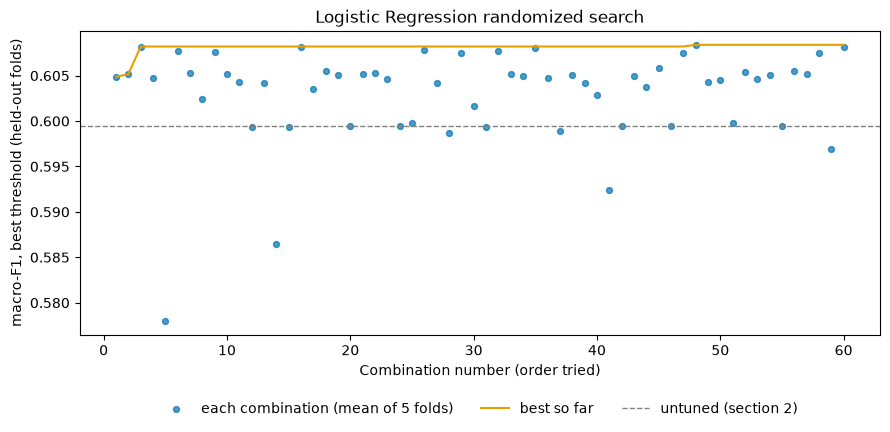

Best settings:
  model__C: 0.1209
  model__l1_ratio: 0.8833
  splines: SplineTransformer(n_knots=10)


In [6]:
# Each combination's held-out macro-F1 (best threshold), in the order they were tried, and the best score so far
untuned_best_threshold_f1 = np.mean([best_threshold_macro_f1(y_train.iloc[valid_index], untuned_probabilities[valid_index])
                                     for _, valid_index in folds])

fig, ax = plt.subplots(figsize=(9, 4.5))
tried = results_df["mean_test_macro_f1_best_threshold"].to_numpy()
ax.scatter(np.arange(1, len(tried) + 1), tried, s=18, color="#0072B2", alpha=0.7, label="each combination (mean of 5 folds)")
ax.plot(np.arange(1, len(tried) + 1), np.maximum.accumulate(tried), color="#E69F00", label="best so far")
ax.axhline(untuned_best_threshold_f1, color="gray", ls="--", lw=1, label="untuned (section 2)")
ax.set_xlabel("Combination number (order tried)")
ax.set_ylabel("macro-F1, best threshold (held-out folds)")
ax.set_title("Logistic Regression randomized search")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

best_params = search.best_params_
print("Best settings:")
for name, value in best_params.items():
    print(f"  {name}: {value:.4g}" if isinstance(value, float) else f"  {name}: {value}")

### Reading the Search
- **The best combination reaches 0.608** macro-F1 at its best threshold, vs. 0.600 for the untuned model scored the same way (dashed line).
- **The spline features are what matters.** The chart shows three bands (median scores): combinations without splines score about 0.599 (the same as untuned), splines with 4 or 6 cut points about 0.605, and splines with **10 cut points about 0.608**. The few low points are combinations with a very strong penalty. All of the top 10 use 10 cut points.
- **The penalty settings barely matter.** Within the top 10, `C` ranges from 0.006 to 49 and `l1_ratio` from 0 to 0.97, all with the same score. With only 7 features (even after splines), there is little to overfit.
- **The model doesn't memorize at all:** it scores 0.609 on its training rows and 0.608 on held-out rows. Its limit is what a smooth, simple model can express, not overfitting.
- Splines also lift Disrupted PR-AUC from 0.280 to about 0.32, close to the tuned boosting models.

## 6. Tuned vs. Untuned
Get out-of-fold probabilities for the best settings (same folds), and compare with the untuned model **fold by fold**. Because both models are scored on exactly the same rows in each fold, the fold-by-fold difference shows whether the improvement is consistent or just noise.

The main comparison gives **each model its own Disrupted threshold**, chosen on the other 4 folds (the honest method from section 7), because that is how the final model will be used. The default-rule scores are shown too.

Note: the best settings were chosen using these same 5 folds, so the tuned score is slightly optimistic (it was the luckiest of 60 tries on these folds). The final test-set score in the comparison notebook will show the real number.

In [7]:
tuned_model = search.best_estimator_
tuned_probabilities = cross_val_predict(tuned_model, X_train, y_train, cv=folds, method="predict_proba")
tuned_fold_scores = score_folds(y_train, tuned_probabilities, folds)   # default rule

# Each model with its own threshold, chosen on the other 4 folds and scored on the held-out fold
untuned_threshold_scores = cross_validated_threshold(y_train, untuned_probabilities, folds).drop(columns="threshold")
tuned_threshold_fold_scores = cross_validated_threshold(y_train, tuned_probabilities, folds)
tuned_threshold_scores = tuned_threshold_fold_scores.drop(columns="threshold")

comparison = pd.DataFrame({
    "untuned, default rule": untuned_fold_scores.mean(),
    "tuned, default rule": tuned_fold_scores.mean(),
    "untuned, own threshold": untuned_threshold_scores.mean(),
    "tuned, own threshold": tuned_threshold_scores.mean(),
    "change with thresholds (mean)": (tuned_threshold_scores - untuned_threshold_scores).mean(),
    "change (std across folds)": (tuned_threshold_scores - untuned_threshold_scores).std(),
    "folds improved (of 5)": (tuned_threshold_scores > untuned_threshold_scores).sum(),
})
comparison.round(3)

,"untuned, default rule","tuned, default rule","untuned, own threshold","tuned, own threshold",change with thresholds (mean),change (std across folds),folds improved (of 5)
macro_f1,0.520,0.527,0.594,0.601,0.007,0.003,5
f1_normal,0.689,0.687,0.689,0.687,-0.001,0.002,3
f1_delayed,0.635,0.646,0.761,0.770,0.009,0.004,5
f1_disrupted,0.238,0.249,0.333,0.346,0.013,0.011,4
disrupted_precision,0.140,0.148,0.275,0.320,0.045,0.017,5
disrupted_recall,0.790,0.794,0.424,0.382,-0.043,0.043,1
disrupted_pr_auc,0.280,0.323,0.280,0.323,0.043,0.015,5
roc_auc_ovr,0.832,0.836,0.832,0.836,0.004,0.001,5


### Reading the Comparison
- **With their own thresholds, tuning improves macro-F1 by about 0.007 (0.594 -> 0.601), on all 5 folds**, and Disrupted PR-AUC by about 0.043 (0.280 -> 0.323), also on all 5 folds. The spline features make the model better at recognizing disruptions.
- **The untuned Logistic Regression was much better than 03 suggested.** With the default rule it scores 0.520, but with its own threshold 0.594, already close to the untuned tree models. In 03 it looked weak mostly because the class weights make it flag far too many rows as Disrupted under the default rule (recall 0.79, precision 0.14).
- **A simple model gets close to the tree models.** Tuned, it reaches 0.601 macro-F1 and 0.323 PR-AUC, within about 0.01 of the best tuned model. Its decision rule is a smooth curve per feature, which is much easier to explain to the business.

## 7. Choose the Disrupted Threshold
As in 03, a row is called Disrupted when its Disrupted probability is at least a threshold; otherwise the more likely of Normal and Delayed is predicted. Thresholds from 0.05 to 0.95 in steps of 0.01 are tried.

**How the threshold is chosen:** the one with the **highest macro-F1**. This is the default until the team agrees on the cost of a missed disruption vs. a false alarm (see the recall-target table below for an alternative).

**How it is scored honestly:** a threshold chosen and scored on the same rows looks better than it really is. So, for each fold, the threshold is chosen on the **other 4 folds** and then scored on this fold, which it never saw (`cross_validated_threshold` in `tuning_setup.py`). The threshold saved for the final model is chosen on all training rows.

In [8]:
threshold_fold_scores = tuned_threshold_fold_scores   # from section 6
final_threshold = choose_threshold(y_train, tuned_probabilities)

threshold_comparison = pd.DataFrame({
    "default rule (mean)": tuned_fold_scores.mean(),
    "chosen threshold (mean)": threshold_fold_scores.drop(columns="threshold").mean(),
    "change (mean)": (threshold_fold_scores.drop(columns="threshold") - tuned_fold_scores).mean(),
    "folds improved (of 5)": (threshold_fold_scores.drop(columns="threshold") > tuned_fold_scores).sum(),
})
print("Threshold chosen in each fold (on the other 4 folds):", threshold_fold_scores["threshold"].tolist())
print("Final threshold (chosen on all training rows):", final_threshold)
threshold_comparison.round(3)

Threshold chosen in each fold (on the other 4 folds): [0.82, 0.85, 0.85, 0.82, 0.85]
Final threshold (chosen on all training rows): 0.85


,default rule (mean),chosen threshold (mean),change (mean),folds improved (of 5)
macro_f1,0.527,0.601,0.074,5
f1_normal,0.687,0.687,0.000,0
f1_delayed,0.646,0.770,0.124,5
f1_disrupted,0.249,0.346,0.097,5
disrupted_precision,0.148,0.320,0.172,5
disrupted_recall,0.794,0.382,-0.412,0
disrupted_pr_auc,0.323,0.323,0.000,0
roc_auc_ovr,0.836,0.836,0.000,0


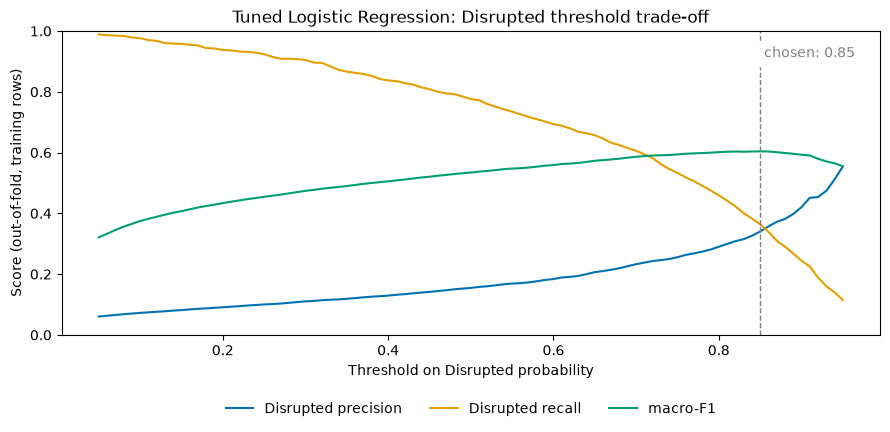

In [9]:
# The full trade-off for the tuned model (out-of-fold, all training rows)
trade_off = pd.DataFrame([
    {"threshold": t, **score_predictions(y_train, tuned_probabilities, t),
     "rows flagged Disrupted": int((predict_with_threshold(tuned_probabilities, t) == DISRUPTED).sum())}
    for t in THRESHOLDS
]).set_index("threshold")

fig, ax = plt.subplots(figsize=(9, 4.5))
for column, color, label in [("disrupted_precision", "#0072B2", "Disrupted precision"),
                             ("disrupted_recall", "#E69F00", "Disrupted recall"),
                             ("macro_f1", "#009E73", "macro-F1")]:
    ax.plot(trade_off.index, trade_off[column], color=color, label=label)
ax.axvline(final_threshold, color="gray", ls="--", lw=1)
ax.text(final_threshold, 0.95, f" chosen: {final_threshold}", color="gray", va="top", backgroundcolor="white")
ax.set_xlabel("Threshold on Disrupted probability")
ax.set_ylabel("Score (out-of-fold, training rows)")
ax.set_ylim(0, 1)
ax.set_title("Tuned Logistic Regression: Disrupted threshold trade-off")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

### Alternative: a Recall Target
If the team decides that catching disruptions matters more than avoiding false alarms, a threshold can instead be chosen to reach a **recall target**: the highest threshold that still catches at least that share of real disruptions. The table shows what each target would cost in precision and false alarms.

In [10]:
recall_target_rows = []
for target in [0.5, 0.6, 0.7, 0.8, 0.9]:
    meets_target = trade_off[trade_off["disrupted_recall"] >= target]
    if meets_target.empty:
        # Even the lowest threshold tried doesn't catch this share of disruptions
        recall_target_rows.append({"recall target": target, "threshold": "not reachable"})
        continue
    threshold = meets_target.index.max()
    row = trade_off.loc[threshold]
    caught = row["disrupted_recall"] * (y_train == DISRUPTED).sum()
    recall_target_rows.append({
        "recall target": target,
        "threshold": threshold,
        "disrupted_recall": row["disrupted_recall"],
        "disrupted_precision": row["disrupted_precision"],
        "macro_f1": row["macro_f1"],
        "false alarms per disruption caught": (row["rows flagged Disrupted"] - caught) / caught,
    })

pd.DataFrame(recall_target_rows).set_index("recall target").round(3)

,threshold,disrupted_recall,disrupted_precision,macro_f1,false alarms per disruption caught
recall target,,,,,
0.5,0.77,0.506,0.268,0.597,2.728
0.6,0.70,0.606,0.233,0.586,3.298
0.7,0.59,0.702,0.181,0.557,4.526
0.8,0.45,0.809,0.141,0.520,6.076
0.9,0.30,0.905,0.110,0.474,8.057


### Reading the Threshold Results
- **The chosen threshold improves macro-F1 by about 0.074 over the default rule, on all 5 folds**, the biggest jump of all the algorithms. The thresholds chosen in each fold are stable (0.82 to 0.85), and the final threshold is **0.85**.
- Why so high: the class weights make the model's Disrupted probabilities much larger than the real chance of a disruption. A threshold around 0.85 undoes that push.
- The trade-off: Disrupted precision doubles (0.15 -> 0.32) but recall falls (0.79 -> 0.38).
- **Recall targets** (from the table): catching 50% of disruptions costs about 2.7 false alarms per disruption caught (threshold 0.77), 70% costs about 4.5 (0.59), and 90% about 8.1 (0.30), about the same as the tuned boosting models.

## 8. Save the Results
Saved to `results/tuning/logistic_regression/` in the shared format, so the comparison notebook can load every algorithm the same way:
- `best_params.json`: the best settings and the chosen Disrupted threshold
- `cv_fold_scores.csv`: the tuned model's scores on each fold, with the chosen threshold (from section 7, chosen on the other folds)
- `out_of_fold_probabilities.csv`: each training row's out-of-fold probabilities, with `date`, `route_id` and the true status
- `search_results.csv`: every combination tried in the search, best first

In [11]:
folder = save_tuning_results(
    model_name="Logistic Regression",
    best_params=best_params,
    fold_scores_df=threshold_fold_scores,
    out_of_fold_probabilities=tuned_probabilities,
    train_df=train_df,
    threshold=final_threshold,
    search_results_df=search_results_df,
)
print("Saved to", folder)

Saved to ../results/tuning\logistic_regression


## 9. Summary
**Setup:** randomized search over spline features, penalty strength and penalty type (60 combinations), stratified 5-fold cross-validation on the training rows (same folds as 03), balanced class weights. Settings chosen by **macro-F1 at their best Disrupted threshold**. The test set was not used.

**Results (mean over the 5 folds; each model with its own threshold, chosen on the other 4 folds)**

| | macro-F1 | Disrupted F1 | Disrupted precision | Disrupted recall | Disrupted PR-AUC |
|---|---|---|---|---|---|
| Untuned (03 settings) | 0.594 | 0.333 | 0.275 | 0.424 | 0.280 |
| **Tuned** (splines, threshold 0.85) | **0.601** | **0.346** | 0.320 | 0.382 | **0.323** |

**What we learned**
1. With its own threshold, even the untuned Logistic Regression (0.594) is far better than its 03 score (0.520) suggested.
2. Spline features are the useful "tuning": they let the model learn curved relationships and lift Disrupted PR-AUC from 0.280 to 0.323. The penalty settings barely matter.
3. Tuned, this simple and explainable model is within about 0.01 macro-F1 of the best tuned model, which suggests the signal in the 7 features is mostly smooth and simple.

**Saved:** `results/tuning/logistic_regression/` (best settings, threshold 0.85, fold scores, out-of-fold probabilities, all search results).

**Next steps**
- Compare all five tuned models (LightGBM, Random Forest, CatBoost, XGBoost, Logistic Regression) in one notebook, using the saved results in `results/tuning/`.
- Agree as a team on what the final model should optimize: macro-F1 (current default), or a recall target. The recall-target table shows what each target costs in false alarms.
- Score the chosen model **once** on the test set, and also report the score for test rows from 2026-06-07 onward.